# **Problem Statement**

Analyze student performance data using machine learning techniques to classify final grades, group students with similar learning patterns, and predict exam scores.


# **Objective**

1. Apply a classification model to predict `FinalGrade`.
2. Apply clustering to identify groups of students with similar learning patterns.
3. Build a regression model to predict `ExamScore`.
4. Evaluate the models and visualize the results.


# Step - 1: Import the required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


# Step - 2: Upload and load the dataset

In [4]:
# Upload the student performance CSV file from your computer
uploaded = files.upload()


Saving student_performance.csv to student_performance.csv


In [5]:
# Read the uploaded CSV file into a DataFrame
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Use the first 1000 rows, as required for the project
df = df.head(1000)

# Display the shape of the dataset
print("Shape of the data:", df.shape)

# Display the column names
print("\nColumn names:")
print(df.columns.tolist())

# Display the first five rows
df.head()


Shape of the data: (1000, 16)

Column names:
['StudyHours', 'Attendance', 'Resources', 'Extracurricular', 'Motivation', 'Internet', 'Gender', 'Age', 'LearningStyle', 'OnlineCourses', 'Discussions', 'AssignmentCompletion', 'ExamScore', 'EduTech', 'StressLevel', 'FinalGrade']


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2


# Step - 3: Describe the data

In [6]:
# Display the data types and non-null counts
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   StudyHours            1000 non-null   int64
 1   Attendance            1000 non-null   int64
 2   Resources             1000 non-null   int64
 3   Extracurricular       1000 non-null   int64
 4   Motivation            1000 non-null   int64
 5   Internet              1000 non-null   int64
 6   Gender                1000 non-null   int64
 7   Age                   1000 non-null   int64
 8   LearningStyle         1000 non-null   int64
 9   OnlineCourses         1000 non-null   int64
 10  Discussions           1000 non-null   int64
 11  AssignmentCompletion  1000 non-null   int64
 12  ExamScore             1000 non-null   int64
 13  EduTech               1000 non-null   int64
 14  StressLevel           1000 non-null   int64
 15  FinalGrade            1000 non-null   int64
dtypes: int6

In [7]:
# Display descriptive statistics for numeric columns
df.describe()


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.0000,1000.000000,1000.000000,1000.000000,1000.000000
mean,19.127000,80.510000,1.076000,0.638000,0.905000,0.923000,0.624000,23.789000,1.492000,10.129000,0.60200,73.8550,71.126000,0.636000,1.234000,1.413000
std,4.558031,11.463215,0.687529,0.480819,0.681498,0.266725,0.484622,3.487785,1.105965,6.556321,0.48973,14.5607,18.429427,0.481389,0.813576,1.178907
min,8.000000,60.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.000000,0.000000,0.000000,0.00000,50.0000,40.000000,0.000000,0.000000,0.000000
25%,17.000000,69.000000,1.000000,0.000000,0.000000,1.000000,0.000000,21.000000,1.000000,4.000000,0.00000,62.0000,54.000000,0.000000,1.000000,0.000000
50%,19.000000,80.000000,1.000000,1.000000,1.000000,1.000000,1.000000,24.000000,1.500000,10.500000,1.00000,73.0000,72.000000,1.000000,1.000000,1.000000
75%,22.000000,89.000000,2.000000,1.000000,1.000000,1.000000,1.000000,27.000000,2.000000,16.000000,1.00000,87.0000,88.000000,1.000000,2.000000,3.000000
max,31.000000,100.000000,2.000000,1.000000,2.000000,1.000000,1.000000,29.000000,3.000000,20.000000,1.00000,100.0000,100.000000,1.000000,2.000000,3.000000


## Check for Null Values

In [8]:
# Count missing values in each column
df.isnull().sum()


,0
StudyHours,0
Attendance,0
Resources,0
Extracurricular,0
Motivation,0
Internet,0
Gender,0
Age,0
LearningStyle,0
OnlineCourses,0


# Step - 4: Separate the features and labels

For classification, `FinalGrade` is the label to be predicted. The remaining selected columns are the input features.


In [9]:
# Select the input features for classification
classification_features = [
    "StudyHours", "Attendance", "Resources", "Extracurricular",
    "Motivation", "Internet", "Gender", "Age", "LearningStyle",
    "OnlineCourses", "Discussions", "AssignmentCompletion",
    "EduTech", "StressLevel"
]

# Separate input features (X) and target label (y)
X_class = df[classification_features]
y_class = df["FinalGrade"]


# Step - 5: Split training and test sample sets

In [10]:
# Refer to the sklearn train_test_split() method
# Use 80% of the records for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)


# Step - 6: Fit the Classification Model

In [11]:
# Create the Random Forest classification model
classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Fit the model using the training features and training labels
classifier.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

# Step - 7: Perform prediction on the test sample set

In [12]:
# Predict the final grade for the test records
y_pred = classifier.predict(X_test)

# Display the predicted grades
print(y_pred)


[2 3 3 3 1 1 3 3 0 0 1 0 3 3 2 0 0 0 0 2 3 3 0 1 1 3 2 0 2 0 0 3 1 2 1 1 3
 3 0 3 3 2 3 1 0 2 0 2 2 1 0 2 3 2 0 3 1 3 2 3 1 2 0 1 1 3 3 3 1 1 2 1 0 0
 2 0 2 3 2 0 1 2 1 1 2 1 0 0 0 0 0 3 0 3 3 3 1 0 3 3 0 2 0 1 2 3 3 1 1 2 2
 0 0 3 2 0 1 3 0 1 3 3 0 3 3 2 3 0 0 1 0 0 0 3 3 2 2 0 0 1 1 1 2 3 3 0 0 2
 2 0 3 2 0 1 0 1 2 1 0 0 3 2 0 1 0 1 0 3 2 1 0 0 0 0 2 2 3 1 0 2 2 0 0 2 3
 1 0 0 2 3 0 3 0 2 3 0 0 2 2 1]


# Step - 8: Evaluate the performance of the classification model

In [13]:
# Calculate the percentage of correctly predicted grades
accuracy = accuracy_score(y_test, y_pred)

print("Classification Accuracy =", round(accuracy * 100, 2), "%")

# Display precision, recall, and F1-score for each grade
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Accuracy = 99.5 %

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        64
           1       1.00      0.98      0.99        41
           2       1.00      1.00      1.00        44
           3       1.00      1.00      1.00        51

    accuracy                           0.99       200
   macro avg       1.00      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200



# Step - 9: Display the Confusion Matrix

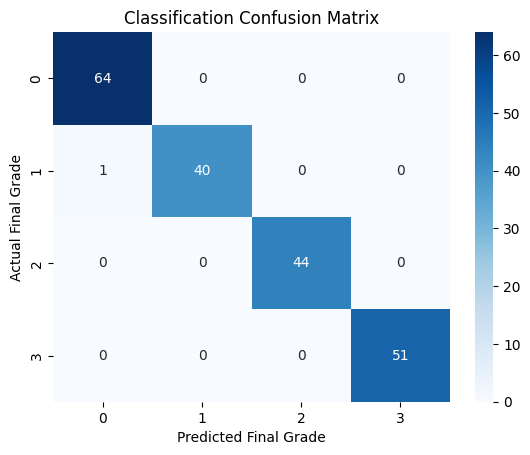

In [14]:
# Compare actual grades with predicted grades
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Final Grade")
plt.ylabel("Actual Final Grade")
plt.title("Classification Confusion Matrix")
plt.show()


# Step - 10: Identify the Important Features

                 Feature  Importance
11  AssignmentCompletion    0.160195
1             Attendance    0.145350
9          OnlineCourses    0.139929
0             StudyHours    0.126158
7                    Age    0.121546
8          LearningStyle    0.080864
13           StressLevel    0.065479
12               EduTech    0.040040
6                 Gender    0.035054
10           Discussions    0.034810
2              Resources    0.016935
4             Motivation    0.016278
3        Extracurricular    0.011535
5               Internet    0.005827


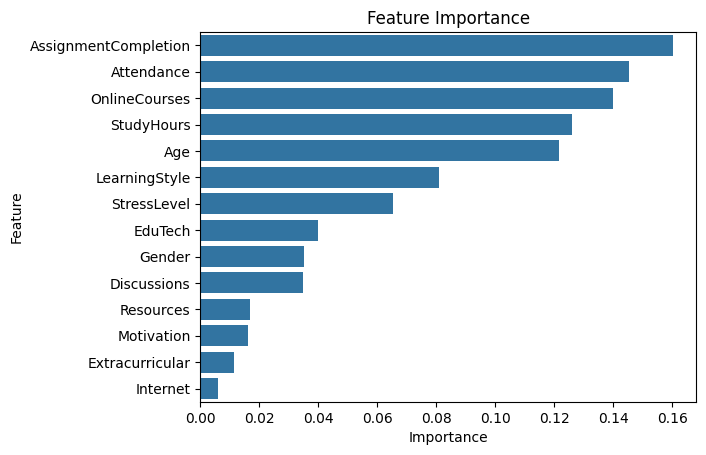

In [15]:
# Show how much each input feature contributes to the classifier
importance = pd.DataFrame({
    "Feature": classification_features,
    "Importance": classifier.feature_importances_
})

importance = importance.sort_values(by="Importance", ascending=False)
print(importance)

# Plot the feature importance values
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()


# Step - 11: Perform Clustering using K-Means

Clustering groups similar student records without using `FinalGrade` as a target label.


In [16]:
# Select features used to group students with similar learning patterns
cluster_features = [
    "StudyHours", "Attendance", "Resources", "Motivation",
    "OnlineCourses", "Discussions", "AssignmentCompletion", "StressLevel"
]

X_cluster = df[cluster_features]

# Standardize the features so that larger numeric scales do not dominate
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Create a K-Means model with three clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit the model and assign each student to a cluster
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Display the number of students in each cluster
print("Number of students in each cluster:")
print(df["Cluster"].value_counts().sort_index())


Number of students in each cluster:
Cluster
0    263
1    365
2    372
Name: count, dtype: int64


# Step - 12: Describe the Clusters

In [17]:
# Calculate the average feature values for each cluster
print(df.groupby("Cluster")[cluster_features].mean().round(2))


         StudyHours  Attendance  Resources  Motivation  OnlineCourses  \
Cluster                                                                 
0             19.65       77.02       1.06        0.89          15.74   
1             19.27       84.46       1.06        0.88           5.53   
2             18.62       79.10       1.10        0.94          10.68   

         Discussions  AssignmentCompletion  StressLevel  
Cluster                                                  
0               1.00                 67.55         1.51  
1               0.93                 82.22         0.97  
2               0.00                 70.10         1.30  


# Step - 13: Plot the Clusters using PCA

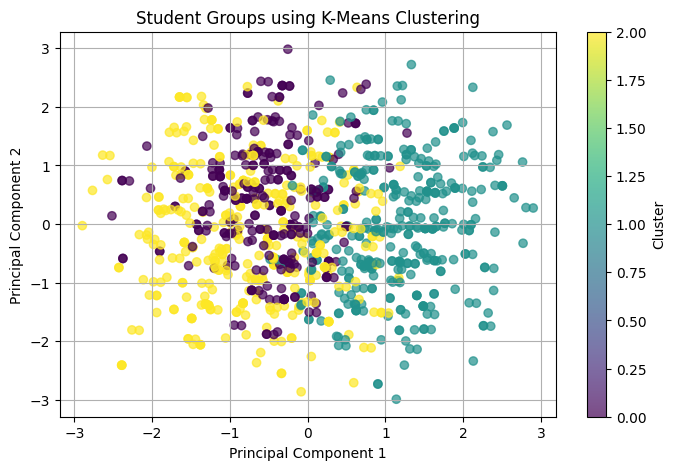

In [18]:
# Reduce the standardized features to two dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the students according to their cluster assignments
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["Cluster"], alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Student Groups using K-Means Clustering")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()


# Step - 14: Separate the features and target for Regression

For regression, `ExamScore` is the numeric target to be predicted.


In [19]:
# Select the input features for exam score prediction
regression_features = [
    "StudyHours", "Attendance", "Resources", "Extracurricular",
    "Motivation", "Internet", "Gender", "Age", "LearningStyle",
    "OnlineCourses", "Discussions", "AssignmentCompletion",
    "EduTech", "StressLevel"
]

# Separate input features (X) and numeric target (y)
X_reg = df[regression_features]
y_reg = df["ExamScore"]


# Step - 15: Split training and test sample sets for Regression

In [20]:
# Split the data into 80% training records and 20% testing records
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)


# Step - 16: Fit the Regression Model

In [21]:
# Create the Random Forest regression model
regressor = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Fit the model using training features and training exam scores
regressor.fit(X_train_reg, y_train_reg)


RandomForestRegressor(random_state=42)

# Step - 17: Perform Prediction on the test sample set

In [22]:
# Predict exam scores for the test records
y_pred_reg = regressor.predict(X_test_reg)

# Display the predicted exam scores
print(y_pred_reg)


[64.57 69.67 53.53 66.58 95.19 47.42 75.   51.29 67.36 49.61 87.   69.58
 69.   45.83 64.14 90.   96.22 90.   70.17 44.14 45.52 56.   82.7  64.36
 59.06 75.52 82.02 71.26 78.54 95.55 50.95 49.52 65.92 62.26 79.99 64.89
 50.16 55.01 48.96 91.52 94.99 87.02 86.64 45.54 52.59 78.87 81.   79.83
 52.11 92.17 46.   89.74 56.45 53.49 94.53 46.01 85.36 65.95 51.73 62.9
 58.19 54.41 84.44 73.12 53.05 85.12 71.77 46.4  90.04 69.12 81.6  62.39
 54.39 63.49 58.19 51.02 77.35 58.75 71.59 60.68 50.68 90.77 56.83 58.69
 86.64 84.44 67.28 95.01 70.32 95.   84.99 91.92 90.13 58.86 97.   52.09
 61.47 83.73 90.94 55.82 69.15 92.96 96.96 73.   68.69 61.1  89.59 83.5
 71.62 81.   90.37 85.57 80.15 52.32 69.58 66.85 95.58 45.9  42.11 58.22
 73.44 65.06 84.   66.17 75.52 46.04 43.68 91.58 44.53 94.78 48.26 67.61
 56.31 50.   64.67 66.06 85.21 73.14 82.82 90.83 40.57 60.   70.   79.13
 48.87 78.09 52.   73.   52.91 85.84 76.89 88.98 45.84 66.35 64.57 97.73
 85.47 77.36 91.5  73.56 80.66 48.2  77.32 61.1  44.4

# Step - 18: Evaluate the performance of the Regression Model

In [23]:
# Calculate the difference between actual and predicted scores
mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)

# Display the regression evaluation metrics
print("MAE =", round(mae, 2))
print("MSE =", round(mse, 2))
print("RMSE =", round(rmse, 2))
print("R2 Score =", round(r2, 2))


MAE = 1.98
MSE = 12.73
RMSE = 3.57
R2 Score = 0.96


# Step - 19: Compare the Actual and Predicted Exam Scores

In [24]:
# Create a table to compare actual scores with predicted scores
comparison = pd.DataFrame({
    "Actual Exam Score": y_test_reg.values,
    "Predicted Exam Score": y_pred_reg
})

comparison.head(10)


,Actual Exam Score,Predicted Exam Score
0,64,64.57
1,70,69.67
2,53,53.53
3,60,66.58
4,96,95.19
5,47,47.42
6,75,75.00
7,50,51.29
8,68,67.36
9,49,49.61


# Step - 20: Plot Actual vs Predicted Exam Scores

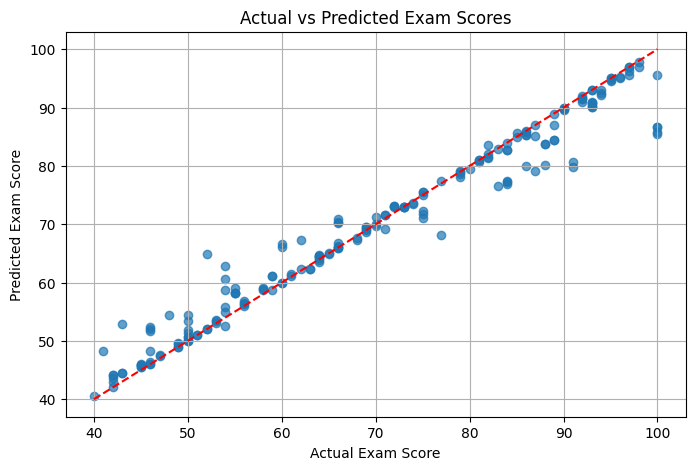

In [25]:
# Plot actual exam scores against the predicted scores
plt.figure(figsize=(8, 5))
plt.scatter(y_test_reg, y_pred_reg, alpha=0.7)

# The diagonal line represents perfect predictions
plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    "r--"
)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs Predicted Exam Scores")
plt.grid(True)
plt.show()


# Step - 21: Predict the Exam Score for a Sample Student

In [26]:
# Select one student from the test dataset
sample_student = X_test_reg.iloc[[0]]

# Get the student's actual exam score
actual_score = y_test_reg.iloc[0]

# Predict the student's exam score using the trained regression model
predicted_score = regressor.predict(sample_student)[0]

print("Actual Exam Score =", actual_score)
print("Predicted Exam Score =", round(predicted_score, 2))


Actual Exam Score = 64
Predicted Exam Score = 64.57


# Conclusion

This notebook applies classification, clustering, and regression to the student performance dataset. The printed evaluation metrics and plots can be used to discuss model performance and the groups identified by clustering. Interpret the results after running all cells in Google Colab.
